<a href="https://colab.research.google.com/github/bhavya1101-cse/aiml-2026-iiith-ihub/blob/main/AIML_Module_2_Lab_4_Text_Representation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


### MODULE 2 LAB 4
### Text Representation


---

## **Section 1: Understanding NLP tools**

In this lab we will be using KNN on a real world NLP application i.e. is text classification. But first look at some NLP techniques for text classification and tools that we use when we want to use python for NLP.

## Section 1.2: Data Cleaning and Preprocessing step

Raw text must be processed and converted into a form so that it is suitable to use with various machine-learning algorithms.  
In case of text, there are lots of things that need to be taken into account.  


1.   Removing numbers from the text
2.   Handling capitalization and punctuation.
3.   Stemming and Lemmatizing text.  

And most importantly, one can't just use words or images directly in algorithms; they need to be converted into vectors- a form that algorithms can understand.



### **NLTK**
NLTK (or Natural Language Tool Kit) is a commonly used library for processing text. We will use this tool in this lab. Lets first install it.


In [ ]:
import nltk
nltk.download('stopwords')
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('averaged_perceptron_tagger_eng')
nltk.download('wordnet')
nltk.download('omw-1.4')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger_eng.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


True

In [ ]:
import re
import numpy
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.stem import SnowballStemmer
from nltk.tokenize import word_tokenize
from nltk import pos_tag
from nltk.corpus import wordnet
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from bs4 import BeautifulSoup

def cleanText(text, lemmatize, stemmer):
    """Method for cleaning text from train and test data. Removes numbers, punctuation, and capitalization. Stems or lemmatizes text."""

    if isinstance(text, float):
        text = str(text)
    if isinstance(text, numpy.int64):
        text = str(text)
    try:
        text = text.decode()
    except AttributeError:
        pass

    soup = BeautifulSoup(text, "lxml")
    text = soup.get_text()
    text = re.sub(r"[^A-Za-z]", " ", text)
    text = text.lower()


    if lemmatize:
        wordnet_lemmatizer = WordNetLemmatizer()

        def get_tag(tag):
            if tag.startswith('J'):
                return wordnet.ADJ
            elif tag.startswith('V'):
                return wordnet.VERB
            elif tag.startswith('N'):
                return wordnet.NOUN
            elif tag.startswith('R'):
                return wordnet.ADV
            else:
                return ''

        text_result = []
        tokens = word_tokenize(text)  # Generate list of tokens
        tagged = pos_tag(tokens)
        for t in tagged:
            try:
                text_result.append(wordnet_lemmatizer.lemmatize(t[0], get_tag(t[1][:2])))
            except:
                text_result.append(wordnet_lemmatizer.lemmatize(t[0]))
        return text_result

    if stemmer:
        text_result = []
        tokens = word_tokenize(text)
        snowball_stemmer = SnowballStemmer('english')
        for t in tokens:
            text_result.append(snowball_stemmer.stem(t))
        return text_result

In [ ]:
sample_text = "Troubling"
sample_text_result = cleanText(sample_text, lemmatize=False, stemmer=True)
sample_text_result = " ".join(str(x) for x in sample_text_result)
print(sample_text)
print(sample_text_result)
sample_text_result = cleanText(sample_text, lemmatize=True, stemmer=False)
sample_text_result = " ".join(str(x) for x in sample_text_result)
print(sample_text_result)

Troubling
troubl
trouble


## Section 1.2: BAG OF WORDS

A bag-of-words model, or BoW for short, is a way of extracting features from text for use in modeling, such as with machine learning algorithms.

The approach is very simple and flexible, and can be used in many ways for extracting features from documents.

A bag-of-words is a representation of text that describes the occurrence of words within a document.
It is called a “bag” of words, because any information about the order or structure of words in the document is discarded. The model is only concerned with whether known words occur in the document, not where in the document.

In [ ]:
5*12

60

In [ ]:
# Functions to convert document(s) to a list of words, with the option of removing stopwords. Returns document-term matrix.

def createBagOfWords(train, test, remove_stopwords, lemmatize, stemmer):
    if remove_stopwords:
        vectorizer = CountVectorizer(analyzer='word', input='content', stop_words=stopwords.words('english'))
    else:
        vectorizer = CountVectorizer(analyzer='word', input='content')

    clean_train = []
    for paragraph in train:
        paragraph_result = cleanText(paragraph, lemmatize, stemmer)
        paragraph = " ".join(str(x) for x in paragraph_result)
        clean_train.append(paragraph)

    clean_test = []
    for paragraph in test:
        paragraph_result = cleanText(paragraph, lemmatize, stemmer)
        paragraph = " ".join(str(x) for x in paragraph_result)
        clean_test.append(paragraph)

    bag_of_words_train = vectorizer.fit_transform(clean_train).toarray()
    bag_of_words_test = vectorizer.transform(clean_test).toarray()
    return bag_of_words_train, bag_of_words_test


In [ ]:
# Visualize how Bag of Words works with a simple example
from sklearn.feature_extraction.text import CountVectorizer

sample_sentences = [
    "I love this movie",
    "This movie is great",
    "I hate this movie"
]

vectorizer = CountVectorizer()
bow_matrix = vectorizer.fit_transform(sample_sentences)

print("Vocabulary (unique words):", vectorizer.get_feature_names_out())
print("\nBag of Words Matrix:")
print(bow_matrix.toarray())
print("\nEach row represents a sentence, each column represents a word count")

Vocabulary (unique words): ['great' 'hate' 'is' 'love' 'movie' 'this']

Bag of Words Matrix:
[[0 0 0 1 1 1]
 [1 0 1 0 1 1]
 [0 1 0 0 1 1]]

Each row represents a sentence, each column represents a word count


## Section 1.3: TF-IDF
TF-IDF technique is used to find meaning of sentences consisting of words and cancels out the incapabilities of Bag of Words technique which is good for text classification or for helping a machine read words in numbers.

The number of times a term occurs in a document is called its Term frequency (TF).

 Document frequency is the number of documents in which the word is present.  Inverse DF (IDF) is the inverse of the document frequency which measures the informativeness of term *t*.




In [ ]:
def createTFIDF(train, test, remove_stopwords, lemmatize, stemmer):
    if remove_stopwords:
        vectorizer = TfidfVectorizer(analyzer='word', input='content', stop_words=stopwords.words('english'))
    else:
        vectorizer =  TfidfVectorizer(analyzer='word', input='content')

    clean_train = []
    for paragraph in train:
        paragraph_result = cleanText(paragraph, lemmatize, stemmer)
        paragraph = " ".join(str(x) for x in paragraph_result)
        clean_train.append(paragraph)

    clean_test = []
    for paragraph in test:
        paragraph_result = cleanText(paragraph, lemmatize, stemmer)
        paragraph = " ".join(str(x) for x in paragraph_result)
        clean_test.append(paragraph)

    tfidf_train = vectorizer.fit_transform(clean_train).toarray()
    tfidf_test = vectorizer.transform(clean_test).toarray()
    return tfidf_train, tfidf_test

In [ ]:
# Compare BoW vs TF-IDF on the same example
from sklearn.feature_extraction.text import TfidfVectorizer

sample_sentences = [
    "I love this movie",
    "This movie is great",
    "I hate this movie"
]

tfidf_vectorizer = TfidfVectorizer()
tfidf_matrix = tfidf_vectorizer.fit_transform(sample_sentences)

print("TF-IDF Matrix:")
print(tfidf_matrix.toarray())
print("\nNotice: Common words like 'movie' have lower scores")
print("Unique words like 'love', 'hate', 'great' have higher scores")

TF-IDF Matrix:
[[0.         0.         0.         0.76749457 0.45329466 0.45329466]
 [0.6088451  0.         0.6088451  0.         0.35959372 0.35959372]
 [0.         0.76749457 0.         0.         0.45329466 0.45329466]]

Notice: Common words like 'movie' have lower scores
Unique words like 'love', 'hate', 'great' have higher scores


# **Section 2: UNDERSTANDING THE DATA : A REVIEWS DATASET**

Sentiment analysis is the interpretation and classification of emotions (such as positive, negative and neutral) within text data using text analysis techniques.  
Given below is a dataset consisting of reviews along with sentiment class (positive or negative).

In [ ]:
# Upload the Reviews CSV file that has been shared with you.
# Run this cell, click on the 'Choose files' button and upload the file.
from google.colab import files
uploaded = files.upload()

Saving reviews.csv to reviews.csv


In [ ]:
import pandas as pd
df = pd.read_csv('reviews.csv')

In [ ]:
df = df.dropna()

In [ ]:
df

,sentence,sentiment
0,This movie was excellent and I loved it,1
1,"Terrible film, waste of time",0
2,Amazing performance by the actors,1
3,Boring and predictable plot,0
4,One of the best movies I've seen,1
...,...,...
995,Completely disappointed with this movie,0
996,Fantastic storyline and direction,1
997,Poor acting and bad script,0
998,"Highly recommended, must watch",1


In [ ]:
df.to_csv('reviews.csv', index=False)

In [ ]:
# Explore the dataset to understand its structure
print("Dataset Shape:", df.shape)
print("\nFirst few rows:")
print(df.head())

print("\nClass Distribution:")
print(df['sentiment'].value_counts())

print("\nSample Reviews:")
for i in range(3):
    print(f"\nReview {i+1}: {df['sentence'].iloc[i]}")
    print(f"Sentiment: {df['sentiment'].iloc[i]}")

Dataset Shape: (1000, 2)

First few rows:
                                  sentence  sentiment
0  This movie was excellent and I loved it          1
1             Terrible film, waste of time          0
2        Amazing performance by the actors          1
3              Boring and predictable plot          0
4         One of the best movies I've seen          1

Class Distribution:
sentiment
1    500
0    500
Name: count, dtype: int64

Sample Reviews:

Review 1: This movie was excellent and I loved it
Sentiment: 1

Review 2: Terrible film, waste of time
Sentiment: 0

Review 3: Amazing performance by the actors
Sentiment: 1


# **Section 3: KNN MODEL**

Given below are two KNN models; in the first case we are using Bag-of-Words and in the second case we are using TF-IDF.
Note the different metrics and parameters used in each.

In [ ]:
from sklearn import metrics, neighbors
from sklearn.model_selection import train_test_split, cross_val_score, cross_val_predict

## TASK - 1: Tweak the models below and see results with different parameters and distance metrics.

def bow_knn():
    """Method for determining nearest neighbors using bag-of-words and K-Nearest Neighbor algorithm"""

    training_data = pd.read_csv('reviews.csv')
    X_train, X_test, y_train, y_test = train_test_split(training_data["sentence"], training_data["sentiment"], test_size=0.2, random_state=5)
    X_train, X_test = createBagOfWords(X_train, X_test, remove_stopwords=True, lemmatize=True, stemmer=False)
    # print(X_train)
    knn = neighbors.KNeighborsClassifier(n_neighbors=5, weights='uniform', algorithm='auto', leaf_size=30, p=2, metric='euclidean', metric_params=None, n_jobs=1)

    knn.fit(X_train, y_train)
    predicted = knn.predict(X_test)
    acc = metrics.accuracy_score(y_test, predicted)
    print('KNN with BOW accuracy = ' + str(acc * 100) + '%')

    scores = cross_val_score(knn, X_train, y_train, cv=3)
    print("Cross Validation Accuracy: %0.2f" % (scores.mean()))
    print(scores)
    print('\n')
    return predicted, y_test


def tfidf_knn():
    """Method for determining nearest neighbors using tf-idf and K-Nearest Neighbor algorithm"""

    training_data = pd.read_csv('reviews.csv')
    X_train, X_test, y_train, y_test = train_test_split(training_data["sentence"], training_data["sentiment"],
                                                        test_size=0.2, random_state=5)
    X_train, X_test = createTFIDF(X_train, X_test, remove_stopwords=True, lemmatize=True, stemmer=False)
    # print(X_train)
    knn = neighbors.KNeighborsClassifier(n_neighbors=5, weights='distance', algorithm='brute', leaf_size=30, p=2,
                                         metric='cosine', metric_params=None, n_jobs=1)

    knn.fit(X_train, y_train)
    predicted = knn.predict(X_test)
    acc = metrics.accuracy_score(y_test, predicted)
    print('KNN with TFIDF accuracy = ' + str(acc * 100) + '%')

    scores = cross_val_score(knn, X_train, y_train, cv=3)
    print("Cross Validation Accuracy: %0.2f" % (scores.mean()))
    print(scores)
    return predicted, y_test

Note: Cross-validation will be discussed in detail in the upcoming lab session.

In [ ]:
## KNN accuracy after using BoW
predicted, y_test = bow_knn()

KNN with BOW accuracy = 100.0%
Cross Validation Accuracy: 1.00
[1. 1. 1.]




In [ ]:
## KNN accuracy after using TFIDF
predicted, y_test = tfidf_knn()

KNN with TFIDF accuracy = 100.0%
Cross Validation Accuracy: 1.00
[1. 1. 1.]


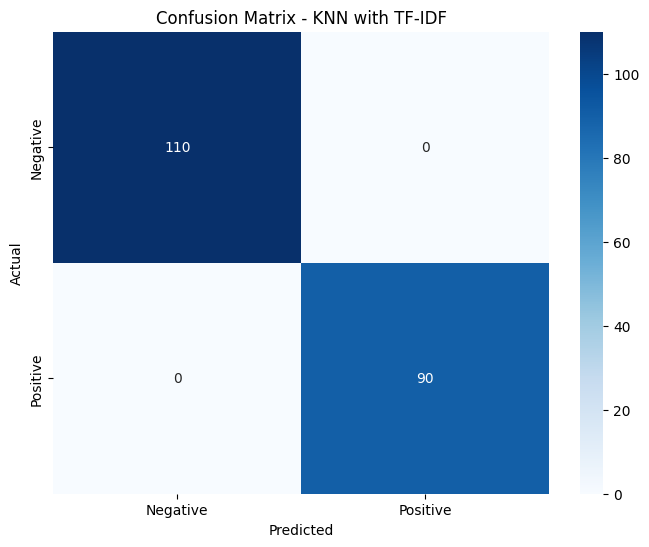


Detailed Classification Report:
              precision    recall  f1-score   support

    Negative       1.00      1.00      1.00       110
    Positive       1.00      1.00      1.00        90

    accuracy                           1.00       200
   macro avg       1.00      1.00      1.00       200
weighted avg       1.00      1.00      1.00       200



In [ ]:
# Visualize model performance with confusion matrix
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

# Create confusion matrix
cm = confusion_matrix(y_test, predicted)

# Plot
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Negative', 'Positive'],
            yticklabels=['Negative', 'Positive'])
plt.title('Confusion Matrix - KNN with TF-IDF')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()

print("\nDetailed Classification Report:")
print(classification_report(y_test, predicted, target_names=['Negative', 'Positive']))

---
## TASK 1: My experiments on the reviews dataset

Both models above scored **100%**. Before changing any settings, it's worth checking *why* the score is perfect.

In [ ]:
# First, let's look closely at the reviews dataset
from sklearn import neighbors, metrics
from sklearn.model_selection import train_test_split
import numpy as np
import pandas as pd

reviews = pd.read_csv('reviews.csv')
print("Total reviews:", len(reviews))
print("Unique review sentences:", reviews['sentence'].nunique())
print()
print(reviews.drop_duplicates().to_string(index=False))

# Same split as bow_knn() / tfidf_knn() above
Xr_train, Xr_test, yr_train, yr_test = train_test_split(reviews["sentence"], reviews["sentiment"],
                                                        test_size=0.2, random_state=5)
overlap = Xr_test.isin(set(Xr_train)).mean() * 100
print(f"\nTest reviews that also appear word-for-word in the training set: {overlap:.0f}%")

Total reviews: 1000
Unique review sentences: 10

                               sentence  sentiment
This movie was excellent and I loved it          1
           Terrible film, waste of time          0
      Amazing performance by the actors          1
            Boring and predictable plot          0
       One of the best movies I've seen          1
Completely disappointed with this movie          0
      Fantastic storyline and direction          1
             Poor acting and bad script          0
         Highly recommended, must watch          1
              Not worth watching at all          0

Test reviews that also appear word-for-word in the training set: 100%


**Important observation:** the reviews file has 1000 rows, but only **10 different sentences**, each repeated 100 times. After the 80/20 split, **every test review also appears word-for-word in the training set**. So KNN only has to find the identical copy (distance = 0) and copy its label. The 100% doesn't show that the model understands sentiment. The test is too easy, because the model is tested on reviews it has already seen.

In [ ]:
# TASK 1: try different k values, weights and distance metrics on the reviews data
rev_bow_train, rev_bow_test = createBagOfWords(Xr_train, Xr_test, remove_stopwords=True, lemmatize=True, stemmer=False)
rev_tfidf_train, rev_tfidf_test = createTFIDF(Xr_train, Xr_test, remove_stopwords=True, lemmatize=True, stemmer=False)

rows = []
for rep_name, (tr, te) in {"BoW": (rev_bow_train, rev_bow_test), "TF-IDF": (rev_tfidf_train, rev_tfidf_test)}.items():
    for k in [1, 5, 25, 75, 151, 301]:
        for w in ["uniform", "distance"]:
            for m in ["euclidean", "manhattan", "cosine"]:
                knn = neighbors.KNeighborsClassifier(n_neighbors=k, weights=w, metric=m, algorithm="brute")
                pred = knn.fit(tr, yr_train).predict(te)
                rows.append({"features": rep_name, "k": k, "weights": w, "metric": m,
                             "accuracy %": round(metrics.accuracy_score(yr_test, pred) * 100, 1)})

rev_results = pd.DataFrame(rows)
print(rev_results.pivot_table(index=["features", "weights", "metric"], columns="k", values="accuracy %"))

k                              1      5      25     75     151    301
features weights  metric                                             
BoW      distance cosine     100.0  100.0  100.0  100.0  100.0  100.0
                  euclidean  100.0  100.0  100.0  100.0  100.0  100.0
                  manhattan  100.0  100.0  100.0  100.0  100.0  100.0
         uniform  cosine     100.0  100.0  100.0  100.0   86.5   76.5
                  euclidean  100.0  100.0  100.0  100.0   86.5   76.5
                  manhattan  100.0  100.0  100.0  100.0   86.5   76.5
TF-IDF   distance cosine     100.0  100.0  100.0  100.0  100.0  100.0
                  euclidean  100.0  100.0  100.0  100.0  100.0  100.0
                  manhattan  100.0  100.0  100.0  100.0  100.0  100.0
         uniform  cosine     100.0  100.0  100.0  100.0   86.5   76.5
                  euclidean  100.0  100.0  100.0  100.0   86.5   76.5
                  manhattan  100.0  100.0  100.0  100.0   86.5   62.0


**What I observed when tweaking the parameters (TASK 1):**

- **k from 1 to 75:** 100% for every combination of features (BoW / TF-IDF), weights and distance metric (euclidean / manhattan / cosine). Each sentence has about 80 identical copies in the training set, so all of the first ~75 neighbours are exact copies with the correct label.
- **k = 151 and 301 with `weights='uniform'`:** accuracy drops to **86.5%** and **76.5%** (62% for TF-IDF + manhattan). Now each prediction is a vote among 151 or 301 reviews, which must include many copies of *other* sentences, often with the opposite sentiment. With equal votes, those outvote the correct copies.
- **`weights='distance'` stays at 100% even at k = 301.** Identical copies have distance 0, and sklearn then uses **only** the zero-distance neighbours, so the far-away reviews don't matter.
- **The metric made no difference here.** Every test sentence has exact copies, so all three metrics find the same nearest neighbours.

**Conclusion:** on this dataset, the parameters only matter when k is very large. `weights='distance'` is the safer choice because closer neighbours count more. Because of the duplicates, though, the dataset is too small and repetitive to really compare BoW with TF-IDF or the different metrics. The spam dataset in Section 4 is a much better test.

In [ ]:
# A fairer test: reviews the model has NEVER seen, written with different words
new_reviews = [
    "The acting was excellent and the story was amazing",
    "What a fantastic film, I loved every minute",
    "Brilliant cast and a wonderful soundtrack",
    "A truly enjoyable and heartwarming experience",
    "The plot was terrible and boring",
    "I hated this film, total waste of money",
    "Dull characters and an awful ending",
    "Weak story and the jokes fell flat",
]
new_labels = np.array([1, 1, 1, 1, 0, 0, 0, 0])

# Train on ALL 1000 reviews, test on the 8 new ones
full_tfidf, new_tfidf = createTFIDF(reviews["sentence"], new_reviews, remove_stopwords=True, lemmatize=True, stemmer=False)
knn = neighbors.KNeighborsClassifier(n_neighbors=5, weights="distance", metric="cosine", algorithm="brute")
new_pred = knn.fit(full_tfidf, reviews["sentiment"]).predict(new_tfidf)

for text, true, pred, vec in zip(new_reviews, new_labels, new_pred, new_tfidf):
    known = "no known words!" if vec.sum() == 0 else ""
    print(f"{'OK   ' if true == pred else 'WRONG'} | true={true} predicted={pred} | {text}  {known}")
print(f"\nAccuracy on new, unseen reviews: {metrics.accuracy_score(new_labels, new_pred) * 100:.1f}%")

OK    | true=1 predicted=1 | The acting was excellent and the story was amazing  
OK    | true=1 predicted=1 | What a fantastic film, I loved every minute  
OK    | true=1 predicted=1 | Brilliant cast and a wonderful soundtrack  no known words!
OK    | true=1 predicted=1 | A truly enjoyable and heartwarming experience  no known words!
OK    | true=0 predicted=0 | The plot was terrible and boring  
OK    | true=0 predicted=0 | I hated this film, total waste of money  
WRONG | true=0 predicted=1 | Dull characters and an awful ending  no known words!
WRONG | true=0 predicted=1 | Weak story and the jokes fell flat  no known words!

Accuracy on new, unseen reviews: 75.0%


**What happened with new, unseen reviews:**

- The 4 reviews that share words with the training data ("excellent", "amazing", "fantastic", "loved", "terrible", "boring", "waste") were all classified **correctly**.
- The other 4 reviews ("Brilliant cast...", "Dull characters and an awful ending", ...) contain **no word from the training vocabulary**. Their TF-IDF vector is all zeros, so the model has no information about them. It gave all 4 the same label (positive). That was right for the 2 positive ones only by luck, and wrong for "Dull characters and an awful ending" and "Weak story and the jokes fell flat".

So the real accuracy on new data is **75%**, and only because of a lucky default. This shows a key weakness of **BoW and TF-IDF**: they only know the exact words seen during training. "awful" is treated as completely unrelated to "terrible", and "brilliant" as unrelated to "excellent". Word embeddings (Question 2 below) fix this by giving similar words similar vectors.

# Section 4: SPAM TEXT DATASET
Now let's use what we've learnt to classify texts as spam or not spam.

In [ ]:
# Upload the spam text data CSV file that has been shared with you. You can also download the file from https://www.kaggle.com/datasets/uciml/sms-spam-collection-dataset
# Run this cell, click on the 'Choose files' button and upload the file.
from google.colab import files
uploaded = files.upload()

Saving spam.csv to spam.csv


In [ ]:
import pandas as pd

# Load spam.csv with encoding fix
df = pd.read_csv('spam.csv', encoding='latin-1')

# Many spam datasets have extra unnamed columns, so we'll select only the first 2
if df.shape[1] > 2:
    df = df.iloc[:, :2]  # Keep only first 2 columns

# Rename columns to standard names
df.columns = ['Category', 'Message']

# Remove any missing values
df = df.dropna()

# Display dataset info
print(f"✓ Dataset loaded successfully!")
print(f"Shape: {df.shape}")
print(f"Columns: {df.columns.tolist()}")
print(f"\nCategory distribution:")
print(df['Category'].value_counts())
print("\nFirst 5 rows:")
df.head()

✓ Dataset loaded successfully!
Shape: (5572, 2)
Columns: ['Category', 'Message']

Category distribution:
Category
ham     4825
spam     747
Name: count, dtype: int64

First 5 rows:


,Category,Message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [ ]:
df['Category'] = df['Category'].map({'ham': 0, 'spam': 1})

In [ ]:
df.head(5)

,Category,Message
0,0,"Go until jurong point, crazy.. Available only ..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives aro..."


In [ ]:
len(df)

5572

In [ ]:
from sklearn import metrics, neighbors
from sklearn.model_selection import train_test_split, cross_val_score, cross_val_predict

## TASK - 2: Tweak the models below and see results with different parameters

def bow_knn():
    """Method for determining nearest neighbors using bag-of-words and K-Nearest Neighbors."""

    # Load data with proper encoding
    training_data = pd.read_csv('spam.csv', encoding='latin-1')

    # Clean the data - keep only first 2 columns if there are more
    if training_data.shape[1] > 2:
        training_data = training_data.iloc[:, :2]
    training_data.columns = ['Category', 'Message']
    training_data = training_data.dropna()

    # Map categories to numeric
    training_data['Category'] = training_data['Category'].map({'ham': 0, 'spam': 1})

    # Split data
    X_train, X_test, y_train, y_test = train_test_split(
        training_data["Message"],
        training_data["Category"],
        test_size=0.2,
        random_state=0
    )

    # Create Bag of Words features
    X_train, X_test = createBagOfWords(X_train, X_test, remove_stopwords=True,
                                        lemmatize=True, stemmer=False)

    # Train KNN model
    knn = neighbors.KNeighborsClassifier(n_neighbors=5, weights='uniform',
                                          metric='euclidean')
    knn.fit(X_train, y_train)

    # Make predictions
    predicted = knn.predict(X_test)

    # Calculate accuracy
    acc = metrics.accuracy_score(y_test, predicted)
    print('KNN with BOW accuracy = ' + str(acc * 100) + '%')

    # Cross-validation
    scores = cross_val_score(knn, X_train, y_train, cv=3)
    print("Cross Validation Accuracy: %0.2f" % (scores.mean()))
    print(scores)
    print('\n')

    return predicted, y_test


def tfidf_knn():
    """Method for determining nearest neighbors using tf-idf and K-Nearest Neighbors."""

    # Load data with proper encoding
    training_data = pd.read_csv('spam.csv', encoding='latin-1')

    # Clean the data - keep only first 2 columns if there are more
    if training_data.shape[1] > 2:
        training_data = training_data.iloc[:, :2]
    training_data.columns = ['Category', 'Message']
    training_data = training_data.dropna()

    # Map categories to numeric
    training_data['Category'] = training_data['Category'].map({'ham': 0, 'spam': 1})

    # Split data
    X_train, X_test, y_train, y_test = train_test_split(
        training_data["Message"],
        training_data["Category"],
        test_size=0.2,
        random_state=0
    )

    # Create TF-IDF features
    X_train, X_test = createTFIDF(X_train, X_test, remove_stopwords=True,
                                   lemmatize=True, stemmer=False)

    # Train KNN model
    knn = neighbors.KNeighborsClassifier(n_neighbors=5, weights='distance',
                                          metric='cosine', metric_params=None)
    knn.fit(X_train, y_train)

    # Make predictions
    predicted = knn.predict(X_test)

    # Calculate accuracy
    acc = metrics.accuracy_score(y_test, predicted)
    print('KNN with TFIDF accuracy = ' + str(acc * 100) + '%')

    # Cross-validation
    scores = cross_val_score(knn, X_train, y_train, cv=3)
    print("Cross Validation Accuracy: %0.2f" % (scores.mean()))
    print(scores)

    return predicted, y_test

In [ ]:
# This cell may take some time to run
predicted, y_test = bow_knn()

KNN with BOW accuracy = 90.94170403587444%
Cross Validation Accuracy: 0.91
[0.91049798 0.91318977 0.90505051]




In [ ]:
# This cell may take some time to run
predicted, y_test = tfidf_knn()

KNN with TFIDF accuracy = 96.7713004484305%


Cross Validation Accuracy: 0.97
[0.97106326 0.9730821  0.96835017]


---
## TASK 2: My experiments on the spam dataset

The cell above is the lab's `tfidf_knn()`. It reaches **96.77%** accuracy, compared with **90.94%** for `bow_knn()`.

But this dataset is **unbalanced**: most messages are ham. So besides accuracy, I also look at:
- **Spam recall:** what % of the real spam messages we caught.
- **Spam precision:** when we say "spam", how often we're right.
- **Spam F1:** one score that balances recall and precision. This is the most useful single number here.

To make the experiments fast, I clean the text and build the BoW and TF-IDF features **once**, then try many KNN settings on them.

In [ ]:
# TASK 2: build the features ONCE (cleaning is the slow part), then try many KNN settings quickly
import time
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

spam_data = pd.read_csv('spam.csv', encoding='latin-1').iloc[:, :2]
spam_data.columns = ['Category', 'Message']
spam_data = spam_data.dropna()
spam_data['Category'] = spam_data['Category'].map({'ham': 0, 'spam': 1})

# Same split as the lab's functions
S_train, S_test, s_ytrain, s_ytest = train_test_split(spam_data["Message"], spam_data["Category"],
                                                      test_size=0.2, random_state=0)
print(f"Test set: {len(s_ytest)} messages, of which {s_ytest.sum()} are spam")
print(f"A 'model' that always says HAM would already get {(s_ytest == 0).mean() * 100:.2f}% accuracy!\n")

start = time.time()
spam_bow_train, spam_bow_test = createBagOfWords(S_train, S_test, remove_stopwords=True, lemmatize=True, stemmer=False)
spam_tfidf_train, spam_tfidf_test = createTFIDF(S_train, S_test, remove_stopwords=True, lemmatize=True, stemmer=False)
print(f"Features built in {time.time() - start:.0f}s | vocabulary size = {spam_bow_train.shape[1]} words")

def spam_scores(pred):
    """Accuracy plus how well we catch spam (recall), how often a 'spam' label is right (precision), and F1."""
    return {"accuracy %": round(accuracy_score(s_ytest, pred) * 100, 2),
            "spam recall %": round(recall_score(s_ytest, pred) * 100, 1),
            "spam precision %": round(precision_score(s_ytest, pred, zero_division=0) * 100, 1),
            "spam F1 %": round(f1_score(s_ytest, pred) * 100, 1)}

Test set: 1115 messages, of which 166 are spam
A 'model' that always says HAM would already get 85.11% accuracy!



Features built in 11s | vocabulary size = 5808 words


Spam F1 % for every setting (higher is better):
k                              1     3     5     11    21
features metric    weights                               
BoW      cosine    distance  90.1  90.9  88.5  85.5  86.0
                   uniform   90.1  89.1  85.1  81.0  80.7
         euclidean distance  79.7  75.2  71.3  63.9  59.9
                   uniform   79.7  67.7  56.9  35.6  18.6
TF-IDF   cosine    distance  90.6  90.1  87.9  87.2  87.6
                   uniform   90.6  87.1  82.8  82.5  81.8
         euclidean distance  80.1  76.6  73.8  64.5  58.1
                   uniform   80.1  67.7  57.5  35.6   9.2

Top 5 settings:
features  k  weights metric  accuracy %  spam recall %  spam precision %  spam F1 %
     BoW  3 distance cosine       97.49           84.3              98.6       90.9
  TF-IDF  1  uniform cosine       97.40           83.7              98.6       90.6
  TF-IDF  1 distance cosine       97.40           83.7              98.6       90.6
     BoW  1  unifor

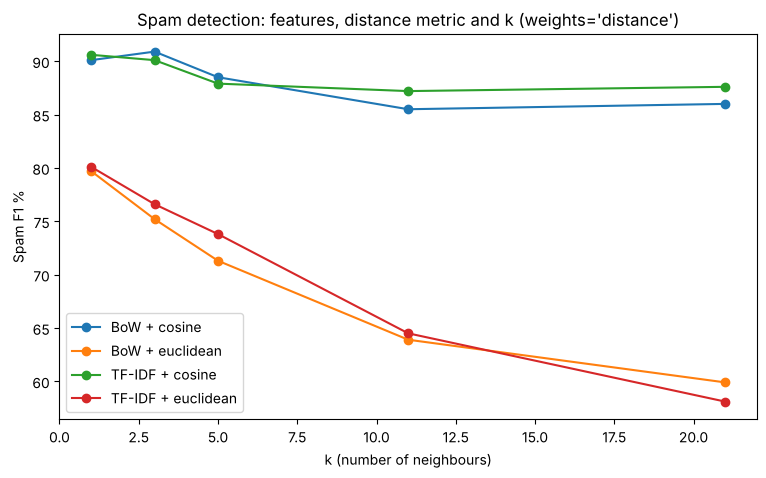

In [ ]:
rows = []
for rep_name, (tr, te) in {"BoW": (spam_bow_train, spam_bow_test), "TF-IDF": (spam_tfidf_train, spam_tfidf_test)}.items():
    for k in [1, 3, 5, 11, 21]:
        for w in ["uniform", "distance"]:
            for m in ["euclidean", "cosine"]:
                knn = neighbors.KNeighborsClassifier(n_neighbors=k, weights=w, metric=m, algorithm="brute")
                pred = knn.fit(tr, s_ytrain).predict(te)
                rows.append({"features": rep_name, "k": k, "weights": w, "metric": m, **spam_scores(pred)})

spam_results = pd.DataFrame(rows)
print("Spam F1 % for every setting (higher is better):")
print(spam_results.pivot_table(index=["features", "metric", "weights"], columns="k", values="spam F1 %"))
print("\nTop 5 settings:")
print(spam_results.sort_values("spam F1 %", ascending=False).head(5).to_string(index=False))
print("\nThe lab's original settings:")
orig = spam_results[((spam_results.features == "BoW") & (spam_results.k == 5) & (spam_results.weights == "uniform") & (spam_results.metric == "euclidean")) |
                    ((spam_results.features == "TF-IDF") & (spam_results.k == 5) & (spam_results.weights == "distance") & (spam_results.metric == "cosine"))]
print(orig.to_string(index=False))

# Plot: effect of k for each features + metric combo (distance weighting)
fig, ax = plt.subplots(figsize=(9, 5))
for (rep_name, m), grp in spam_results[spam_results.weights == "distance"].groupby(["features", "metric"]):
    ax.plot(grp.k, grp["spam F1 %"], marker="o", label=f"{rep_name} + {m}")
ax.set_xlabel("k (number of neighbours)"); ax.set_ylabel("Spam F1 %")
ax.set_title("Spam detection: features, distance metric and k (weights='distance')")
ax.legend(); plt.show()

**What I observed (TASK 2):**

- **Accuracy alone is misleading.** Always predicting "ham" already gives **85.11%**. The lab's BoW model reaches 91.03% accuracy but catches only **39.8%** of the spam messages (F1 56.9%). Most spam gets through.
- **The distance metric matters most.** With **cosine** distance, spam F1 is about 85–91% for every k. With **euclidean** distance, it falls from about 80% (k = 1) to as low as 9–19% (k = 21, uniform). BoW + cosine was about as good as TF-IDF + cosine. Cosine compares the **direction** of the word vectors (which words are used, and in what proportion), not the message length, so a short spam text can still match a long one.
- **k:** for euclidean, larger k is much worse. For cosine, the best values were small (k = 1 to 3), and F1 dropped slightly for larger k. There are 6× more ham than spam messages, so a large neighbourhood is usually dominated by ham.
- **weights:** `'distance'` was better than `'uniform'` in almost every case (e.g. BoW + euclidean, k = 21: 59.9% vs 18.6% F1), because the closest and most similar messages count more.
- **Best setting:** **BoW + cosine, k = 3, weights = 'distance'**: 97.49% accuracy, 84.3% spam recall, 98.6% precision, **F1 90.9%**. That's better than both of the lab's original settings (F1 56.9% and 87.9%).

*Extra detail:* after cleaning, 15 short ham messages (like "What you doing?how are you?") have **no words left** and become all-zero vectors. With euclidean distance, a zero vector sits at the same, fairly small distance from every message, so these empty ham messages often end up as "nearest neighbours" and pull predictions towards ham. Cosine distance doesn't have this problem.

In [ ]:
# Does the text cleaning help? Fix the model (k=3, distance weights, cosine) and change only the preprocessing.
best_knn = lambda: neighbors.KNeighborsClassifier(n_neighbors=3, weights="distance", metric="cosine", algorithm="brute")
rows = []

for sw in [True, False]:
    for lem, stem in [(True, False), (False, True)]:
        start = time.time()
        tr, te = createTFIDF(S_train, S_test, remove_stopwords=sw, lemmatize=lem, stemmer=stem)
        secs = time.time() - start
        rows.append({"preprocessing": f"lab cleaning, stopwords removed={sw}, {'lemmatize' if lem else 'stem'}",
                     "features": tr.shape[1], "clean time s": round(secs, 1), **spam_scores(best_knn().fit(tr, s_ytrain).predict(te))})

# Variants using TfidfVectorizer directly on the raw text (keeps numbers like phone numbers and prices)
variants = {
    "raw text, single words": TfidfVectorizer(),
    "raw text, words + word pairs (bigrams)": TfidfVectorizer(ngram_range=(1, 2)),
    "raw text, character 2-5 grams": TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), sublinear_tf=True),
}
for name, vec in variants.items():
    start = time.time()
    tr = vec.fit_transform(S_train); te = vec.transform(S_test)
    rows.append({"preprocessing": name, "features": tr.shape[1], "clean time s": round(time.time() - start, 1),
                 **spam_scores(best_knn().fit(tr, s_ytrain).predict(te))})

print(pd.DataFrame(rows).to_string(index=False))

digits_spam = spam_data[spam_data.Category == 1].Message.str.contains(r"[0-9]").mean() * 100
digits_ham = spam_data[spam_data.Category == 0].Message.str.contains(r"[0-9]").mean() * 100
print(f"\nMessages containing a number: spam = {digits_spam:.0f}%, ham = {digits_ham:.0f}%")

                                   preprocessing  features  clean time s  accuracy %  spam recall %  spam precision %  spam F1 %
 lab cleaning, stopwords removed=True, lemmatize      5808           5.9       97.31           81.9             100.0       90.1
      lab cleaning, stopwords removed=True, stem      5479           2.1       96.95           79.5             100.0       88.6
lab cleaning, stopwords removed=False, lemmatize      5930           5.3       97.76           86.1              98.6       92.0
     lab cleaning, stopwords removed=False, stem      5598           2.6       97.76           86.1              98.6       92.0
                          raw text, single words      7612           0.1       98.12           88.0              99.3       93.3
          raw text, words + word pairs (bigrams)     42709           0.2       97.94           87.3              98.6       92.7
                   raw text, character 2-5 grams     68938           0.9       98.57           91

**What I observed about preprocessing:**

- **Lemmatization vs stemming:** almost the same accuracy (F1 90.1% vs 88.6% with stopwords removed, and identical without stopword removal), but stemming was about **2–3× faster** (2.1 s vs 5.9 s).
- **Removing stopwords slightly hurt** (F1 90.1% → 92.0% when keeping them). Common short words like "you", "your", "now" and "for" are on the stopword list, but they carry useful signal in SMS spam ("Call now for your free prize").
- **The lab's cleaning removes all numbers, and that throws away a strong clue.** **95% of spam messages contain a number** (phone numbers, prices, short codes), compared with only 16% of ham. Simply using `TfidfVectorizer` on the raw text (which keeps numbers) gave **F1 93.3%**, better than any cleaned version, and was 50× faster.
- **Character n-grams worked best: F1 95.0%, accuracy 98.57%, spam recall 91.0%.** They split text into small pieces of 2–5 letters ("fre", "free", "ree "), so they still match misspellings and SMS shortcuts like "txt", "msg", "2day", "FREE!!", which whole-word methods treat as completely different words.

**Lesson:** preprocessing should fit the data. Rules that help for movie reviews (remove numbers and stopwords) can **remove useful information** for SMS spam.

### Questions to Think About and Answer
1. Why does the TF-IDF approach generally result in a better accuracy than Bag-of-Words ?
2. Can you think of techniques that are better than both BoW and TF-IDF ?
3. Read about Stemming and Lemmatization from the resources given below. Think about the pros/cons of each.

---
## Answers to the Questions

**1. Why does the TF-IDF approach generally result in a better accuracy than Bag-of-Words?**

Bag-of-Words just **counts** how many times each word appears, so every word gets the same importance. Very common words that appear in almost every message ("go", "get", "ok", "call", "movie") get big counts but tell us very little about the class, and they dominate the distance between documents.

TF-IDF fixes this by multiplying the word count (**TF**, term frequency) by **IDF** (inverse document frequency), which is **high for rare words and low for common words**:
- A word in almost every document gets a low weight, because it isn't informative. In the lab's example, "movie" and "this" got 0.45 while "love", "hate" and "great" got 0.77.
- A word found in only a few documents ("prize", "claim", "urgent", "ringtone") gets a high weight, because it's a strong clue.

TF-IDF vectors are also **normalised to length 1**, so long and short messages can be compared fairly. With BoW counts, a long message is far from everything simply because it has more words.

So with TF-IDF, the distance between two documents depends mostly on the **important, distinctive words** they share, which is exactly what KNN needs to find truly similar neighbours. In the lab, TF-IDF got **96.77%** on spam vs **90.94%** for BoW.

*Note from my experiments:* part of the lab's improvement also comes from the **distance metric**. The TF-IDF model used cosine and the BoW model used euclidean. When both use cosine, they score about the same (F1 87.9–90.9% for both), because cosine also ignores message length. Both changes (TF-IDF weighting and length-normalised comparison) push in the same direction: compare documents by **which informative words they use**, not by raw counts.

**2. Can you think of techniques that are better than both BoW and TF-IDF?**

Yes. BoW and TF-IDF have three main weaknesses: (a) **no word order** ("not good" vs "good, not bad" look similar), (b) **no meaning**, since "awful" and "terrible" are completely unrelated words to them (seen in my unseen-reviews test), and (c) **huge, sparse vectors** (5,800+ columns, mostly zeros). Better techniques:

1. **N-grams:** include pairs or triples of words ("not good", "free entry", "call now") to keep some word order. **Character n-grams** handle spelling variations and SMS slang. In my spam experiment, character 2–5 grams gave the best result: **F1 95.0%**, vs 90.1% for the lab's TF-IDF.
2. **Word embeddings: Word2Vec, GloVe, FastText.** Each word becomes a dense vector of about 100–300 numbers learned from huge amounts of text, so **words with similar meanings get similar vectors** ("awful" ≈ "terrible", "brilliant" ≈ "excellent"). A sentence can be represented by averaging its word vectors. FastText also uses character pieces, so it can handle new or misspelled words.
3. **Document embeddings: Doc2Vec, Sentence-BERT / sentence-transformers.** These produce a single vector for a whole sentence or document that captures its overall meaning. They're very good for similarity search, which is exactly what KNN does.
4. **Contextual embeddings from transformers: BERT, RoBERTa, GPT-style models.** The vector for a word depends on the sentence it's in ("bank" in "river bank" vs "bank account"), and the model understands word order, negation and context. Fine-tuned BERT models are the current state of the art for sentiment analysis and spam detection.
5. **Topic models: LSA (TruncatedSVD on TF-IDF) and LDA.** These compress thousands of word columns into a few "topics", reducing sparsity and grouping related words (similar to PCA from Lab 2).

Changing the **classifier** also helps. Naive Bayes, Logistic Regression and linear SVM are usually faster and more accurate than KNN on TF-IDF features, because KNN struggles with very high-dimensional sparse data.

**3. Stemming vs Lemmatization: pros and cons**

Both reduce words to a common base form so that related words are treated as one ("studies", "studying" → one feature). The cell below compares them on some example words.

In [ ]:
# Stemming vs lemmatization on some example words
from nltk.stem import SnowballStemmer, WordNetLemmatizer
stemmer_demo = SnowballStemmer("english")
lemmatizer_demo = WordNetLemmatizer()

examples = [("studies", "n"), ("studying", "v"), ("better", "a"), ("was", "v"), ("ran", "v"),
            ("running", "v"), ("mice", "n"), ("caring", "v"), ("university", "n"), ("universe", "n"),
            ("generously", "r"), ("troubling", "v")]
print(f"{'word':<12}{'stemmed':<12}{'lemmatized':<12}")
print("-" * 36)
for word, pos in examples:
    print(f"{word:<12}{stemmer_demo.stem(word):<12}{lemmatizer_demo.lemmatize(word, pos):<12}")

word        stemmed     lemmatized  
------------------------------------
studies     studi       study       
studying    studi       study       
better      better      good        
was         was         be          
ran         ran         run         
running     run         run         
mice        mice        mouse       
caring      care        care        
university  univers     university  
universe    univers     universe    
generously  generous    generously  
troubling   troubl      trouble     


**Stemming** chops off word endings using fixed rules (the Snowball/Porter algorithm), without understanding the word.
**Lemmatization** uses a dictionary (WordNet) and the word's part of speech (noun, verb, adjective) to return the real base word, called the **lemma**.

From the example above:
- "studies" → stem **"studi"** (not a real word) vs lemma **"study"**
- "better" → stem "better" vs lemma **"good"** (lemmatization understands irregular forms)
- "was" → "was" vs **"be"**, "ran" → "ran" vs **"run"**, "mice" → "mice" vs **"mouse"**
- "university" and "universe" → both stem to **"univers"** (two different meanings merged), but stay different after lemmatization.

| | Stemming | Lemmatization |
|---|---|---|
| **How it works** | Cuts off suffixes with rules | Dictionary lookup plus part-of-speech |
| **Output** | Often not a real word ("studi", "troubl") | Always a real word ("study", "trouble") |
| **Speed** | **Fast**: 2.1 s on the spam data | Slower: 5.9 s (needs POS tagging and a dictionary) |
| **Accuracy of the base form** | Can **over-stem**: different words merged ("universe"/"university") | More accurate and handles irregular words ("better" → "good", "mice" → "mouse") |
| **Missed matches** | Can **under-stem**: "ran" and "run" stay different | Needs the correct POS tag. Without it, "running" stays "running" |
| **Needs extra resources** | No, just rules | Yes: WordNet dictionary and a POS tagger |
| **Languages** | Easy to build for many languages | Needs a good dictionary for each language |
| **Readability** | Hard to read and interpret | Easy to read and interpret |

**Pros of stemming:** simple, very fast, no dictionary needed, and good enough for search engines and large datasets.
**Cons of stemming:** produces non-words, can merge unrelated words (over-stemming) or miss related ones (under-stemming).

**Pros of lemmatization:** real, meaningful words, handles irregular forms, more precise, which helps when meaning matters (chatbots, question answering).
**Cons of lemmatization:** slower, needs part-of-speech tagging and a dictionary, and can still make mistakes if the POS tag is wrong.

**In my spam experiment** both gave almost the same accuracy (F1 90.1% vs 88.6%), so stemming was the better trade-off there: about the same result, nearly 3× faster. Lemmatization is worth the extra time when the exact meaning of words matters more than speed.

### Useful Resources for further reading
1. Stemming and Lemmatization: https://nlp.stanford.edu/IR-book/html/htmledition/stemming-and-lemmatization-1.html
2. TF-IDF and BoW : https://www.analyticsvidhya.com/blog/2020/02/quick-introduction-bag-of-words-bow-tf-idf/
3. TF-IDF: https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfTransformer.html
